Loyiha vazifasi

Uy narxini (SalePrice) bashorat qilish. AQShning Ames shahridagi ~1460 ta uy haqida 80 ga yaqin feature bor: maydoni, sifati, qurilgan yili, garaji, tumani va boshqalar.

Nega bu qiyinroq?

Feature'lar soni 5 ta emas, ~80 ta
Ko'p ustunlarda bo'sh qiymatlar bor
Matnli ustunlar ko'p (tuman, uy turi, sifat darajasi...)

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

data = fetch_openml(name="house_prices", as_frame=True)
df = data.frame
print(df.shape)

(1460, 81)


1-bosqich: EDA (02-notebook bilimlari)

Vazifa: ma'lumot bilan tanishing.

shape, head(), info() → nechta qator va ustun bor? Qaysilari sonli, qaysilari matnli?
Bo'sh qiymatlar: eng ko'p bo'sh qiymatga ega 10 ta ustunni toping
SalePrice taqsimotining histogrammasini chizing
SalePrice bilan eng kuchli korrelyatsiyaga ega 10 ta sonli feature'ni toping
Eng kuchli 2 ta feature uchun scatter grafik chizing

In [2]:
df.isnull().sum().sort_values(ascending=False).head(10)

corr = df.select_dtypes("number").corr()
corr["SalePrice"].sort_values(ascending=False).head(11)  # 1-o'rinda SalePrice'ning o'zi

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

2-bosqich: Target'ni log'ga o'tkazish (yangi mavzu!)

📖 Izoh: SalePrice histogrammasi o'ngga qiyshiq chiqadi: ko'p uylar o'rtacha narxda, ozgina juda qimmat uylar esa uzun "dum" hosil qiladi. Bunday holda modellar qimmat uylarga haddan tashqari e'tibor beradi.

Yechim: narxning logarifmini bashorat qilish. Shunda taqsimot simmetrikroq bo'ladi va xatolar foizda o'lchanadi: 100 000$ lik uydagi 10 000$ xato ham, 500 000$ lik uydagi 50 000$ xato ham bir xil darajada "jazolanadi". Kaggle ham natijani aynan log ko'rinishida baholaydi.

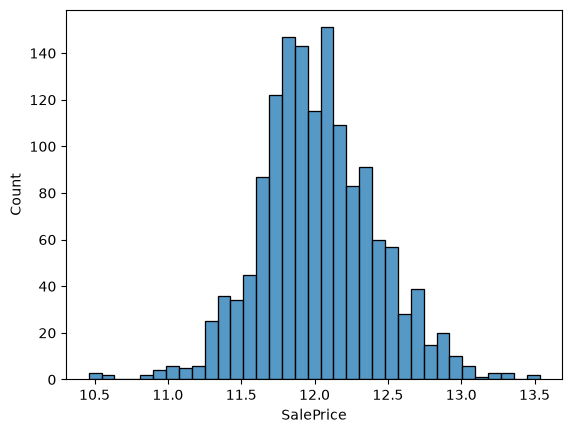

In [3]:
y = np.log1p(df["SalePrice"])   # log(1 + x)
X = df.drop(columns=["SalePrice", "Id"])   # Id shunchaki tartib raqami, narx haqida hech narsa aytmaydi

sns.histplot(y)   # endi taqsimot qanday ko'rinadi?
plt.show()

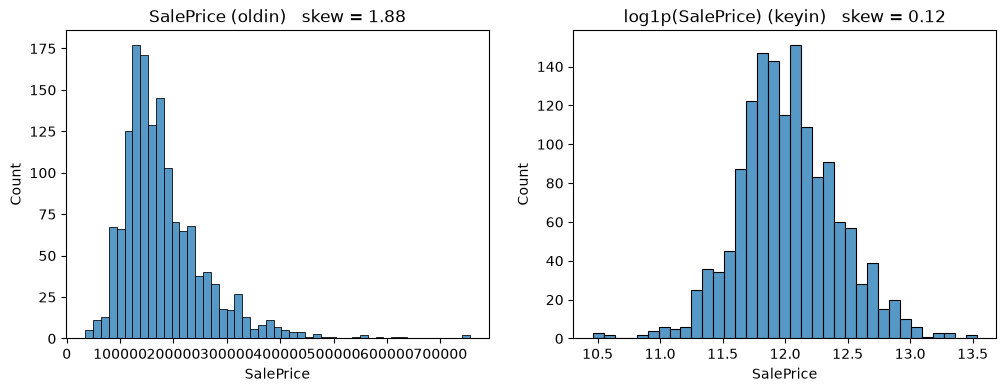

X: (1460, 79)  y: (1460,)


In [4]:
# Oldin va keyin: yonma-yon solishtirish
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["SalePrice"], ax=ax[0])
ax[0].set_title(f"SalePrice (oldin)   skew = {df['SalePrice'].skew():.2f}")

sns.histplot(y, ax=ax[1])
ax[1].set_title(f"log1p(SalePrice) (keyin)   skew = {y.skew():.2f}")
plt.show()

print("X:", X.shape, " y:", y.shape)

In [5]:
# Logdan haqiqiy narxga qaytish: expm1 = exp(x) - 1, ya'ni log1p'ning teskarisi
print("log ko'rinishi:", y.head(3).round(3).tolist())
print("dollarda      :", np.expm1(y.head(3)).round().tolist())
print("asl qiymat    :", df["SalePrice"].head(3).tolist())

log ko'rinishi: [12.248, 12.109, 12.317]
dollarda      : [208500.0, 181500.0, 223500.0]
asl qiymat    : [208500, 181500, 223500]


3-bosqich: Preprocessing Pipeline (04-notebook + 1 ta yangi vosita)

Yangi vosita: SimpleImputer. 02-notebookda bo'sh qatorlarni o'chirgan edik (dropna). Bu yerda esa deyarli har bir qatorda qaysidir bo'sh qiymat bor, shuning uchun o'chirsak, ma'lumot qolmaydi. SimpleImputer bo'sh joylarni to'ldiradi:

sonli ustunlar uchun → strategy="median" (o'rta qiymat)
matnli ustunlar uchun → strategy="most_frequent" (eng ko'p uchraydigan qiymat)

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

# Tekshirish: preprocessor'ni train'da o'rgatib, natijani ko'ramiz
X_train_ready = preprocessor.fit_transform(X_train)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Sonli ustunlar:", len(num_cols), " Matnli ustunlar:", len(cat_cols))
print("Preprocessing'dan keyin:", X_train_ready.shape[1], "ta ustun")


Train: (1168, 79)  Test: (292, 79)
Sonli ustunlar: 36  Matnli ustunlar: 43
Preprocessing'dan keyin: 286 ta ustun


4-bosqich: Modellar bellashuvi (03, 05, 06-notebooklar)

Vazifa: kamida 4 ta modelni cross-validation bilan solishtiring:

LinearRegression
Ridge
RandomForestRegressor
GradientBoostingRegressor

Metrika sifatida RMSE ishlatamiz (log shkalada).

In [7]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, random_state=42),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                             scoring="neg_root_mean_squared_error")
    print(f"{name:<20} RMSE = {-scores.mean():.4f} ± {scores.std():.4f}")

Linear Regression    RMSE = 0.1649 ± 0.0222
Ridge                RMSE = 0.1420 ± 0.0285


Random Forest        RMSE = 0.1468 ± 0.0157


Gradient Boosting    RMSE = 0.1274 ± 0.0165


5-bosqich: Eng yaxshi modelni sozlash (05-notebook)

Vazifa: 4-bosqichdagi eng yaxshi 1–2 ta model uchun GridSearchCV bilan hyperparameter'larni toping.

In [8]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("preprocess", preprocessor),
                 ("model", GradientBoostingRegressor(random_state=42))])   # 4-bosqich g'olibi

param_grid = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__n_estimators":  [300, 600],
    "model__max_depth":     [2, 3, 4],
}   # 3 × 2 × 3 = 18 ta kombinatsiya × 5 fold = 90 ta model

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="neg_root_mean_squared_error",
                    n_jobs=-1)   # barcha protsessor yadrolarida parallel
grid.fit(X_train, y_train)

print(grid.best_params_)
print(f"CV RMSE: {-grid.best_score_:.4f}   (4-bosqichda: 0.1274)")

{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 600}
CV RMSE: 0.1255   (4-bosqichda: 0.1274)


6-bosqich: Yakuniy baholash

Vazifa:

Eng yaxshi modelni test to'plamida baholang: log-RMSE va R²
Bashoratlarni dollarga qaytaring va MAEni dollarda hisoblang
"Haqiqiy narx" va "bashorat" scatter grafigini chizing (ideal holatda nuqtalar diagonal chiziq ustida yotadi)

Test log-RMSE: 0.13567521651493925
Test R²: 0.9013575539385057
O'rtacha xato: $16,235


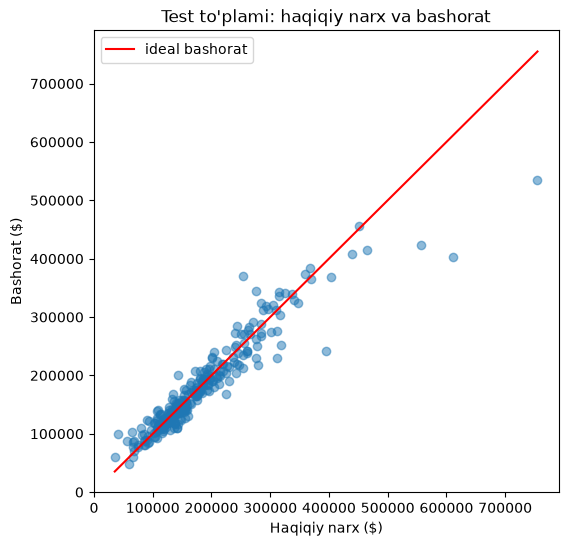

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
best = grid.best_estimator_
y_pred = best.predict(X_test)

print("Test log-RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test R²:", r2_score(y_test, y_pred))

price_true = np.expm1(y_test)
price_pred = np.expm1(y_pred)   # log'dan dollarga qaytarish
print(f"O'rtacha xato: ${mean_absolute_error(price_true, price_pred):,.0f}")

# Haqiqiy narx va bashorat: ideal holatda hamma nuqta qizil diagonal ustida yotadi
plt.figure(figsize=(6, 6))
plt.scatter(price_true, price_pred, alpha=0.5)
lim = [price_true.min(), price_true.max()]
plt.plot(lim, lim, color="red", label="ideal bashorat")
plt.xlabel("Haqiqiy narx ($)")
plt.ylabel("Bashorat ($)")
plt.title("Test to'plami: haqiqiy narx va bashorat")
plt.legend()
plt.show()
